# Unit 3: Training with Strong Targets

[Course overview](00_overview.ipynb)

<ul>
<li><a href="#learn" style="color:#E65100;"><strong>Overview and Learning Objectives</strong></a></li>
<li><a href="#scenario" style="color:black;">Scenario and Dataset</a></li>
<li><a href="#exercise_targets" style="color:#006064;">Exercise 1: Strong to Weak Targets</a></li>
<li><a href="#model" style="color:black;">CNN and Sigmoid</a></li>
<li><a href="#loss_metrics" style="color:black;">Training Loss and Precision, Recall, F-measure</a></li>
<li><a href="#strong_training" style="color:black;">Training with Strong Targets</a></li>
<li><a href="#predictions" style="color:black;">Inspecting Predictions</a></li>
</ul>

<a id="learn"></a>

<div style="
  background-color: #FFE0B2A0;
  border: 1px solid #FFC671A0;
  padding-top: 10px;
  padding-bottom: 10px;
  padding-left: 20px;
  padding-right: 20px;
  margin-top: 10px;
  margin-bottom: 10px;
">

<h2 style="color:#E65100; margin-top:0;">Overview and Learning Objectives</h2>

<p style="color:#E65100;">We now introduce the synthetic frequency-activity scenario from
    Section 5 of the article, create the dataset, inspect the CNN,
    and train a strongly supervised BCE reference. We interpret precision, recall,
    and F-measure before moving to weakly aligned targets.</p>

</div>

In [2]:
from time import perf_counter
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import torch
from torch.utils.data import DataLoader
from ddtw import SDTW

from dataset_multipitch import MultipitchDataset, collate_multipitch
from model import Transcription_CNN

# --- Figure display and style ---
%config InlineBackend.figure_formats = ['svg']
plt.rcParams.update({"font.size": 8, "axes.titlesize": 9})

In [3]:
# config
torch.manual_seed(1)
device = torch.device("cpu")

max_polyphony = 3  # maximum number of simultaneous onsets in the dataset
# activation function for the output layer of the model
output_activation = "sigmoid"
freqs = (30, 35, 40, 45)  # frequencies (Hz) of the sinusoids in the dataset

<a id="scenario"></a>

## Scenario and Dataset


Each waveform is a five-second sum of gated sinusoids sampled at 100 Hz, with
additive Gaussian noise. The four classes are 30, 35, 40, and 45 Hz; at most
three are active simultaneously. Strong targets have shape `(500, 4)` and
specify frequency activity at each frame. Silence is an all-zero vector.
Weak targets retain the ordered state sequence and discard its durations by
removing consecutive duplicate vectors. The train and validation sets contain
256 and 32 independently generated waveforms.

In [4]:
# data
train_data = MultipitchDataset(
    size=256, seed=0, noise_std=0.01, max_polyphony=max_polyphony, freqs=freqs
)
valid_data = MultipitchDataset(
    size=32, seed=1, noise_std=0.01, max_polyphony=max_polyphony, freqs=freqs
)
train_loader = DataLoader(
    train_data,
    batch_size=16,
    shuffle=True,
    collate_fn=collate_multipitch,
    num_workers=0,
)
valid_loader = DataLoader(
    valid_data, batch_size=16, collate_fn=collate_multipitch, num_workers=0
)
class_names = train_data.class_names

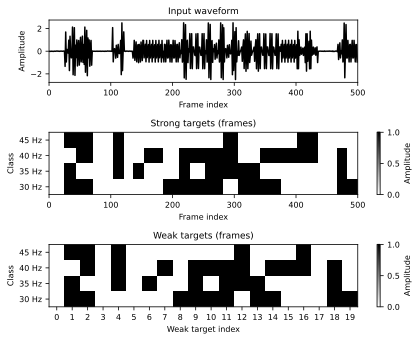

In [5]:
# plot a sample waveform and its corresponding strong and weak targets

(
    test_waveform,
    test_strong_targets_frames,
    test_weak_targets_frames,
    _,
    _,
) = valid_data[0]

fig, ax = plt.subplots(3, 1, figsize=(6.2, 4.8))

im0 = ax[0].plot(np.arange(0, 500, 1), test_waveform[0].numpy(), color="k")
ax[0].set(
    xlim=[0, 500],
    title="Input waveform",
    ylabel="Amplitude",
    xlabel="Frame index",
)

im1 = ax[1].imshow(
    test_strong_targets_frames.numpy().T,
    aspect="auto",
    origin="lower",
    interpolation="None",
    cmap="gray_r",
    extent=[0, 500, -0.5, len(class_names) - 0.5],
)
ax[1].set(
    xlim=[0, 500],
    title="Strong targets (frames)",
    ylabel="Class",
    yticks=np.arange(len(class_names)),
    yticklabels=class_names,
    xlabel="Frame index",
)
plt.colorbar(im1, ax=ax[1], label="Amplitude")
cbar = plt.colorbar(im1, ax=ax[0], label=None)
fig.delaxes(cbar.ax)

im2 = ax[2].imshow(
    test_weak_targets_frames.numpy().T,
    aspect="auto",
    origin="lower",
    interpolation="None",
    cmap="gray_r",
)
ax[2].set(
    title="Weak targets (frames)",
    ylabel="Class",
    yticks=np.arange(len(class_names)),
    yticklabels=class_names,
    xticks=np.arange(0, test_weak_targets_frames.shape[0], 1),
    xlabel="Weak target index",
)
plt.colorbar(im2, ax=ax[2], label="Amplitude")

fig.tight_layout()
plt.show()

<a id="exercise_targets"></a>

<div style="
  background-color: #B2EBF290;
  border: 1px solid #4DD0E190;
  padding-top: 10px;
  padding-bottom: 10px;
  padding-left: 20px;
  padding-right: 20px;
  margin-top: 10px;
  margin-bottom: 10px;
">

<strong style="color:#006064; display:block; break-after:avoid; page-break-after:avoid;">Exercise 1: From Strong to Weak Targets</strong>

<ol style="color:#006064;">
<li>Remove consecutive duplicate rows from the strong targets. Retain a state if it reappears after a different state.</li>
<li>Check equality with the dataset's weak targets.</li>
</ol>

</div>

### Solution: From Strong to Weak Targets

Compare adjacent rows across all frequency channels. Always keep the first
row and then retain a row whenever any channel changes. This discards
durations while preserving the sequence, including repeated nonadjacent
states and silence.

In [6]:
strong = test_strong_targets_frames
keep = torch.cat(
    [
        torch.tensor([True]),
        torch.any(strong[1:] != strong[:-1], dim=1),
    ]
)
weak_from_strong = strong[keep]
torch.testing.assert_close(weak_from_strong, test_weak_targets_frames)
print("Strong / weak lengths:", len(strong), len(weak_from_strong))

Strong / weak lengths: 500 20


<a id="model"></a>

## CNN Definition

The small CNN has a receptive field of 15 samples and returns one output vector per input frame. Convolutions and ReLU layers learn local waveform features. A sigmoid gives one activation probability per frequency class, allowing simultaneous notes and all-zero silence. Unlike when using softmax, these output probabilities need not sum to one.

In [7]:
# initialize model
model_bce = Transcription_CNN(
    num_classes=train_data.num_classes, activation=output_activation
).to(device)
print(model_bce)
print("Trainable parameters:", sum(p.numel() for p in model_bce.parameters()))

Transcription_CNN(
  (output_activation): Sigmoid()
  (layers): Sequential(
    (0): Conv1d(1, 16, kernel_size=(11,), stride=(1,), padding=(5,))
    (1): ReLU()
    (2): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (3): ReLU()
    (4): Conv1d(32, 4, kernel_size=(1,), stride=(1,))
  )
)
Trainable parameters: 2916


<a id="loss_metrics"></a>

## Training Loss and Precision, Recall, F-measure


For aligned predictions $x_{n,k}$ and targets $y_{n,k}$, frame-wise BCE is

$$L_{\rm BCE}=-\frac{1}{NK}\sum_{n,k}
\big[y_{n,k}\log x_{n,k}+(1-y_{n,k})\log(1-x_{n,k})\big].$$

We threshold probabilities at 0.5 to count true positives (TP), false positives
(FP), and false negatives (FN) over frame-frequency pairs:

$$P=\frac{TP}{TP+FP},\qquad R=\frac{TP}{TP+FN},\qquad
F_1=\frac{2PR}{P+R}.$$

The existing loops compute these counts per batch and average the resulting
scores across validation batches. These scores describe frequency activity,
not onset matching. If a denominator is zero, the corresponding score is
undefined; this should be considered when interpreting early-epoch outputs.
The score plots show logged checkpoints: the first epoch and then every ten
epochs. Their horizontal positions index these checkpoints.

<div style="
  background-color: #FFE0B2A0;
  border: 1px solid #FFC671A0;
  padding-top: 10px;
  padding-bottom: 10px;
  padding-left: 20px;
  padding-right: 20px;
  margin-top: 10px;
  margin-bottom: 10px;
">

<h2 style="color:#E65100; margin-top:0;">Attention: Activity Targets and Sigmoid</h2>

<p style="color:#E65100;">
    Multiple frequency classes can be active simultaneously. Sigmoid treats
    them independently and can also represent all-zero silence. Softmax would
    force the outputs to sum to one, which conflicts with these targets.
    </p>

</div>

<a id="strong_training"></a>

## Training with Strong Targets

Frame-wise binary cross-entropy (BCE) compares each prediction directly with its time-aligned target. This provides a reference for the weakly supervised experiments. Validation uses a threshold of 0.5 and reports frame-frequency precision, recall, and F1, averaged over batches.

Epoch   1 | train loss 0.67669 | val loss 0.6654 | val P 0.7223 | val R 0.4249 | val F1 0.5351 | elapsed time 0.2 s
Epoch  10 | train loss 0.27629 | val loss 0.2684 | val P 0.8932 | val R 0.8415 | val F1 0.8666 | elapsed time 0.9 s
Epoch  20 | train loss 0.20661 | val loss 0.2065 | val P 0.9137 | val R 0.8719 | val F1 0.8923 | elapsed time 1.6 s
Epoch  30 | train loss 0.18591 | val loss 0.1857 | val P 0.9192 | val R 0.8951 | val F1 0.9070 | elapsed time 2.4 s
Epoch  40 | train loss 0.17392 | val loss 0.1742 | val P 0.9275 | val R 0.9012 | val F1 0.9142 | elapsed time 3.2 s
Epoch  50 | train loss 0.16564 | val loss 0.1667 | val P 0.9313 | val R 0.9046 | val F1 0.9177 | elapsed time 4.3 s
Epoch  60 | train loss 0.15899 | val loss 0.1605 | val P 0.9340 | val R 0.9105 | val F1 0.9221 | elapsed time 5.1 s
Epoch  70 | train loss 0.15363 | val loss 0.1554 | val P 0.9340 | val R 0.9138 | val F1 0.9238 | elapsed time 5.9 s
Epoch  80 | train loss 0.14899 | val loss 0.1512 | val P 0.9372 | val R 

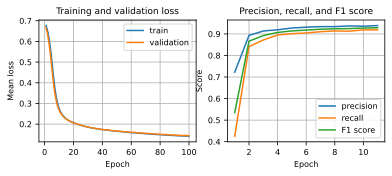

In [8]:
bce_loss = loss_fn = torch.nn.BCELoss()

optimizer = torch.optim.Adam(model_bce.parameters(), lr=0.001)
train_losses, valid_losses, precisions, recalls, fmeasures = [], [], [], [], []
training_start = perf_counter()

for epoch in range(100):
    # train step
    model_bce.train()
    total_loss = 0.0
    for (
        waveforms,
        strong_targets_frames,
        weak_targets_frames,
        strong_targets_onsets,
        weak_targets_onsets,
        target_lengths_frames,
        target_lengths_onsets,
    ) in train_loader:
        optimizer.zero_grad()
        predictions = model_bce(waveforms)

        # compute frame-wise BCE loss between predictions and strong targets
        loss = bce_loss(predictions, strong_targets_frames)

        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(waveforms)
    train_losses.append(total_loss / len(train_data))

    # validation step
    model_bce.eval()
    total_loss = 0.0
    with torch.no_grad():
        p_ = []
        r_ = []
        f_ = []
        for (
            waveforms,
            strong_targets_frames,
            weak_targets_frames,
            strong_targets_onsets,
            weak_targets_onsets,
            target_lengths_frames,
            target_lengths_onsets,
        ) in valid_loader:
            predictions = model_bce(waveforms)
            loss = bce_loss(predictions, strong_targets_frames)
            total_loss += loss.item() * len(waveforms)

            # calculate precision, recall, and F1 score for each batch
            pred_thresh = (predictions > 0.5) * 1.0
            TP = (strong_targets_frames * pred_thresh).sum()
            FP = ((1 - strong_targets_frames) * pred_thresh).sum()
            FN = (strong_targets_frames * (1 - pred_thresh)).sum()
            P = TP / (TP + FP)
            R = TP / (TP + FN)
            F = 2 * P * R / (P + R)
            p_.append(P.item())
            r_.append(R.item())
            f_.append(F.item())

    valid_losses.append(total_loss / len(valid_data))

    # print stats every 10 epochs
    elapsed = perf_counter() - training_start
    if epoch == 0 or (epoch + 1) % 10 == 0:
        print(
            (
                "Epoch %3d | train loss %.5f | val loss %.4f | "
                "val P %.4f | val R %.4f | val F1 %.4f | "
                "elapsed time %.1f s"
            )
            % (
                epoch + 1,
                train_losses[-1],
                valid_losses[-1],
                np.mean(p_),
                np.mean(r_),
                np.mean(f_),
                elapsed,
            )
        )
        precisions.append(np.mean(p_))
        recalls.append(np.mean(r_))
        fmeasures.append(np.mean(f_))

# plot training and validation loss curves
fig, ax = plt.subplots(1, 2, figsize=(6.2, 2.2))
ax[0].plot(np.arange(1, len(train_losses) + 1), train_losses, label="train")
ax[0].plot(
    np.arange(1, len(valid_losses) + 1), valid_losses, label="validation"
)
ax[0].set(
    xlabel="Epoch", ylabel="Mean loss", title="Training and validation loss"
)
ax[0].legend()
ax[0].grid()

ax[1].plot(np.arange(1, len(precisions) + 1), precisions, label="precision")
ax[1].plot(np.arange(1, len(recalls) + 1), recalls, label="recall")
ax[1].plot(np.arange(1, len(fmeasures) + 1), fmeasures, label="F1 score")
ax[1].set(
    xlabel="Epoch", ylabel="Score", title="Precision, recall, and F1 score"
)
ax[1].legend()
ax[1].grid()
plt.show()

<a id="predictions"></a>

## Inspecting Predictions

After training, we compare reference activity, probabilities, thresholded
errors, and individual frequency channels. Black denotes true positives,
red false positives, cyan false negatives, and white true negatives.

In [9]:
(
    test_waveform,
    test_strong_targets_frames,
    test_weak_targets_frames,
    _,
    _,
) = valid_data[0]
pred_strong_bce = model_bce(test_waveform[None])[0]

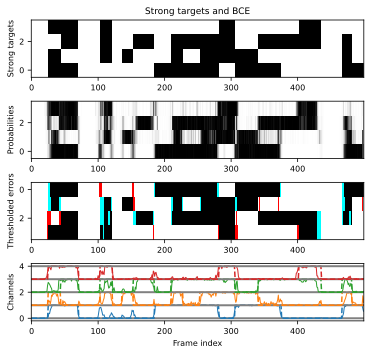

In [10]:
fig, ax = plt.subplots(4, 1, figsize=(5.2, 5), squeeze=False)
# strong targets
ax[0, 0].imshow(
    test_strong_targets_frames.numpy().T,
    aspect="auto",
    origin="lower",
    interpolation="None",
    cmap="gray_r",
    clim=[0, 1],
)

# raw predictions
ax[1, 0].imshow(
    pred_strong_bce.detach().numpy().T,
    aspect="auto",
    origin="lower",
    interpolation="None",
    cmap="gray_r",
    clim=[0, 1],
)

# thresholded predictions
pred_strong_thresh = (pred_strong_bce > 0.5) * 1.0
TP = test_strong_targets_frames * pred_strong_thresh
FP = (1 - test_strong_targets_frames) * pred_strong_thresh
FN = test_strong_targets_frames * (1 - pred_strong_thresh)
TN = (1 - test_strong_targets_frames) * (1 - pred_strong_thresh)
pred_RGB_strong = np.zeros((500, len(class_names), 3))
pred_RGB_strong[TP == 1] = [0, 0, 0]
pred_RGB_strong[FP == 1] = [1, 0, 0]
pred_RGB_strong[FN == 1] = [0, 1, 1]
pred_RGB_strong[TN == 1] = [1, 1, 1]
ax[2, 0].imshow(
    pred_RGB_strong.swapaxes(0, 1), aspect="auto", interpolation="None"
)

# plot individual signals for each class
for d in range(len(class_names)):
    ax[3, 0].plot(np.arange(500), np.zeros(500) + d, color="grey", linewidth=2)
    ax[3, 0].plot(
        np.arange(500),
        pred_strong_bce.detach().numpy()[:, d] + d,
        color=f"C{d}",
        label=class_names[d],
        linewidth=1,
    )
    ax[3, 0].plot(
        np.arange(500),
        test_strong_targets_frames[:, d] + d,
        color=f"C{d}",
        linestyle="--",
    )
    ax[3, 0].grid()
ax[3, 0].plot(np.arange(500), np.zeros(500) + d + 1, color="grey", linewidth=2)
ax[3, 0].set(xlim=[-0.5, 499.5])


ax[0, 0].set(title="Strong targets and BCE", ylabel="Strong targets")
ax[1, 0].set(ylabel="Probabilities")
ax[2, 0].set(ylabel="Thresholded errors")
ax[3, 0].set(ylabel="Channels", xlabel="Frame index")
fig.tight_layout()
plt.show()